FIGURE S2

Shahlo Solieva

Created 07-07-2026

Use this notebook to create histograms of trajectory lengths from the Folding@home simulations.

In [1]:
# import packages
import numpy as np
import h5py
import matplotlib.pyplot as plt

In [2]:
BASE_PATH = '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/clustering/radius_15_variable_subsample50/data/apo/'
FIGURE_PATH='/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/FAH-analysis-20260212/aggregate_sim_times/figures/'

sys_names = ['CH103_naive_VC','CH103_mature_VC',
             'PGT121_naive_VC','PGT121_mature_VC',
             'CH65_naive_VC','CH65_mature_VC',
             'Ab118_naive_VC','Ab118_mature_VC']

titles    = ['Naive CH103','Mature CH103',
             'Naive PGT121','Mature PGT121',
             'Naive CH65','Mature CH65',
             'Naive 1-18','Mature 1-18']
        

In [3]:
def get_n_frames(sys_name):
    n_frames = []
    with h5py.File(f'{BASE_PATH}/{sys_name}/cluster-assignments.h5', 'r') as h5_file:
        # iterate through all arrays in the assignments file, get number of frames.
        for traj in range(len(list(h5_file.keys()))):
            dataset_name = list(h5_file.keys())[traj]
            data = h5_file[dataset_name][:]
            n_frames.append(len(data))

    print(sys_name, 'Number of trajectories:',len(n_frames), '| TOTAL ns:',sum(n_frames)*40/1000,'| max ns:',np.max(n_frames)*40/1000)
    return n_frames

def get_n_frames_CAP(sys_name):
    n_frames = []
    with h5py.File(f'{BASE_PATH}/{sys_name}/cluster-r215-to-reduce-nclusters/cluster-assignments-r215.h5', 'r') as h5_file:
        # iterate through all arrays in the assignments file, get number of frames.
        for traj in range(len(list(h5_file.keys()))):
            dataset_name = list(h5_file.keys())[traj]
            data = h5_file[dataset_name][:]
            n_frames.append(len(data))

    print(sys_name, 'Number of trajectories:',len(n_frames), '| TOTAL ns:',sum(n_frames)*40/1000,'| max ns:',np.max(n_frames)*40/1000)
    return n_frames

In [133]:
def plot_hist(sys_name, title, n_frames):
    plt.figure(figsize=[3,1.8])
    plt.hist(np.array(n_frames)*40/1000, bins=50, color='0.5',
             label=f'Total: {(sum(n_frames)*40/1000):.2f} ns\nAverage: {(np.average(n_frames)*40/1000):.2f} ns')
    #plt.yscale('log')
    plt.ylabel('Number of trajectories', weight='bold',fontsize=6, labelpad=0.2)
    plt.xlabel('Time (ns)', weight='bold', fontsize=6, labelpad=0.2)
    plt.yticks(fontsize=6)
    plt.xticks(fontsize=6)
    plt.ylim(0,50)
    plt.xlim(0,1600)
    plt.title(f'{title}', weight='bold', fontsize=8)
    plt.legend(fontsize=6)
    plt.tight_layout()
    plt.savefig
    #plt.savefig(f"{FIGURE_PATH}/FAH_trajLengths_{sys_name}.pdf", dpi=300, bbox_inches='tight', transparent=True)
    plt.show()

In [ ]:
def plot_broken_hist(sys_name, title, n_frames):
    f, (ax, ax2) = plt.subplots(2, 1, sharex=True, gridspec_kw={"height_ratios": [1, 1]}, figsize=[3,1.2])
    ax.hist( np.array(n_frames)*40/1000, bins=50, color='0.5', label=f'Total: {(sum(n_frames)*40/1000):.2f} ns\nAverage: {(np.average(n_frames)*40/1000):.2f} ns')
    ax2.hist(np.array(n_frames)*40/1000, bins=50, color='0.5')
    ax.legend([f"Total: {(sum(n_frames)*40/1000):.2f} ns\nAverage: {(np.average(n_frames)*40/1000):.2f} ns"], fontsize=6)
    ax.set_ylim(60,1900)  # outliers only
    ax2.set_ylim(0, 60)  # most of the data
    ax.set_yticks([60, 1000, 1900])
    ax2.set_yticks([0,20,40,60])
    ax.set_xlim(0,1600)
    ax.spines['bottom'].set_visible(False)
    ax2.spines['top'].set_visible(False)
    ax.xaxis.tick_top()
    ax.tick_params(top=False,labeltop=False, labelsize=6)  
    ax2.xaxis.tick_bottom()
    ax2.tick_params(labelsize=6)
    ax.set_title(f'{title}', weight='bold', fontsize=8)
    
    d = .015  # how big to make the diagonal lines in axes coordinates
    kwargs = dict(transform=ax.transAxes, color='k', clip_on=False)
    ax.plot((-d, +d), (-d, +d), **kwargs)        # top-left diagonal
    ax.plot((1 - d, 1 + d), (-d, +d), **kwargs)  # top-right diagonal
    kwargs.update(transform=ax2.transAxes)  # switch to the bottom axes
    ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)  # bottom-left diagonal
    ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)  # bottom-right diagonal
    
    f.supylabel('Number of trajectories', weight='bold',fontsize=6,x=-0.01)
    f.supxlabel('Time (ns)', weight='bold',fontsize=6, y=-0.15)
    f.savefig(f"{FIGURE_PATH}/FAH_trajLengths_{sys_name}.pdf", dpi=300, bbox_inches='tight', transparent=True)
    plt.show()

In [43]:
len(custom_bins)

80

In [48]:
def plot_broken_hist(sys_name, title, n_frames):
    f, (ax, ax2) = plt.subplots(2, 1, sharex=True, gridspec_kw={"height_ratios": [1, 1]}, figsize=[3,1.2])
    custom_bins = np.arange(0,1600,20)
    ax.hist( np.array(n_frames)*40/1000, bins=custom_bins, color='0.5', label=f'Total: {(sum(n_frames)*40/1000):.2f} ns\nAverage: {(np.average(n_frames)*40/1000):.2f} ns')
    ax2.hist(np.array(n_frames)*40/1000, bins=custom_bins, color='0.5')
    ax.legend([f"Total: {(sum(n_frames)*40/1000):.2f} ns\nAverage: {(np.average(n_frames)*40/1000):.2f} ns"], fontsize=6)
    ax.set_ylim(50,1900)  # outliers only
    ax2.set_ylim(0, 50)  # most of the data
    ax.set_yticks([50, 1000, 1900])
    ax2.set_yticks([0,25,50])
    ax.set_xlim(0,1600)
    ax.spines['bottom'].set_visible(False)
    ax2.spines['top'].set_visible(False)
    ax.xaxis.tick_top()
    ax.tick_params(top=False,labeltop=False, labelsize=6)  
    ax2.xaxis.tick_bottom()
    ax2.tick_params(labelsize=6)
    ax.set_title(f'{title}', weight='bold', fontsize=8)
    
    d = .015  # how big to make the diagonal lines in axes coordinates
    kwargs = dict(transform=ax.transAxes, color='k', clip_on=False)
    ax.plot((-d, +d), (-d, +d), **kwargs)        # top-left diagonal
    ax.plot((1 - d, 1 + d), (-d, +d), **kwargs)  # top-right diagonal
    kwargs.update(transform=ax2.transAxes)  # switch to the bottom axes
    ax2.plot((-d, +d), (1 - d, 1 + d), **kwargs)  # bottom-left diagonal
    ax2.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)  # bottom-right diagonal
    
    f.supylabel('Number of trajectories', weight='bold',fontsize=6,x=-0.01)
    f.supxlabel('Time (ns)', weight='bold',fontsize=6, y=-0.15)
    f.savefig(f"{FIGURE_PATH}/FAH_trajLengths_{sys_name}.pdf", dpi=300, bbox_inches='tight', transparent=True)
    plt.show()

CAP256_naive_VC Number of trajectories: 1984 | TOTAL ns: 962913.6 | max ns: 755.0


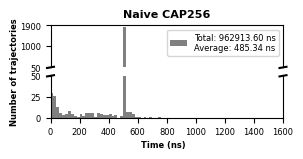

CAP256_mature_VC Number of trajectories: 1994 | TOTAL ns: 1353029.16 | max ns: 724.8


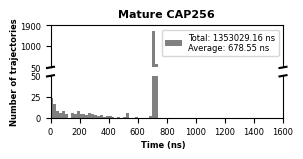

In [49]:
n_frames = get_n_frames_CAP('CAP256_naive_VC')
plot_broken_hist('CAP256_naive_VC', 'Naive CAP256', n_frames)

n_frames = get_n_frames_CAP('CAP256_mature_VC')
plot_broken_hist('CAP256_mature_VC', 'Mature CAP256', n_frames)

CH103_naive_VC Number of trajectories: 1991 | TOTAL ns: 1202185.96 | max ns: 1425.0


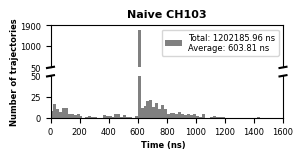

CH103_mature_VC Number of trajectories: 1985 | TOTAL ns: 753703.76 | max ns: 1350.0


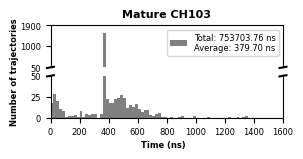

PGT121_naive_VC Number of trajectories: 1995 | TOTAL ns: 398509.44 | max ns: 720.0


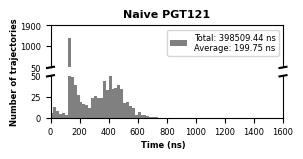

PGT121_mature_VC Number of trajectories: 1995 | TOTAL ns: 1179106.36 | max ns: 1145.0


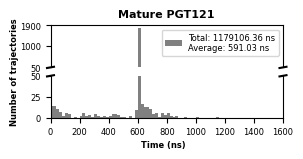

CH65_naive_VC Number of trajectories: 1992 | TOTAL ns: 675575.36 | max ns: 1510.0


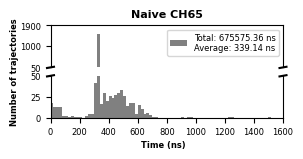

CH65_mature_VC Number of trajectories: 1994 | TOTAL ns: 1290348.8 | max ns: 1550.0


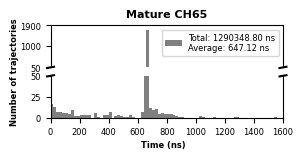

Ab118_naive_VC Number of trajectories: 1991 | TOTAL ns: 975188.04 | max ns: 1325.0


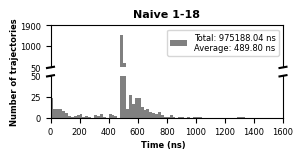

Ab118_mature_VC Number of trajectories: 1994 | TOTAL ns: 673444.76 | max ns: 1300.0


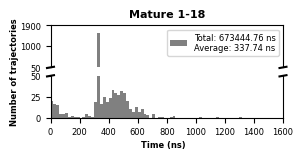

In [50]:
for sys_name,title in zip(sys_names, titles):
    n_frames = get_n_frames(sys_name)
    plot_broken_hist(sys_name, title, n_frames)

In [98]:
totals =[962913.6, 1353029.16, 673444.76, 975188.04, 1290348.8, 675575.36, 1179106.36, 398509.44, 753703.76, 1202185.96]
sum(totals)/1000/1000

9.46400524